# Cell-type AUC under grouped cross-validation

Two cohorts, one question: does a strong supervised AUC survive holding out a
whole group of cells, or is the classifier reading the group rather than the
cell type?

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Each point is one one-vs-all task: the cells of one type against every other
cell. Both panels plot the stricter CV scheme against the standard one, so the
vertical distance below y = x is the AUC lost.

* **a, Zhang 2021 atlas (the Fig. 2 classifiers).** Grouped CV puts every cell
  of a CV group in the same fold; the group is the donor where Zhang et al.
  Table S1 lets it be assigned (heart, LungMAP, islet) and the biosample
  otherwise. Colour is `largest_group_share`, "how concentrated the cell type
  is": the fraction of the type's cells that sit in its single largest group. Holding that group out removes that share of the
  type's training cells, and on this atlas usually the organ context with it,
  so the loss is concentrated in types confined to one or two biosamples. That
  is cross-organ generalisation rather than the cross-donor question.
* **b, Becker 2023 intestine.** Here the question can be asked cleanly:
  NMI(cell type, donor) = 0.035 and every one of the 43 types spans >= 3
  donors, so leave-donor-out CV still leaves positives to learn from. Colour is
  the number of donors carrying the type. Cells were drawn per (type, donor), so
  a type's cell count tracks its donor count and the two cannot be separated.

GSE129785 could not be tested this way -- 4 of its types sit in a single donor.

The numbers a figure legend needs (mean AUCs, Spearman rho, per-bin means) are
printed by the last cell.

Panel:
- `scatac_grouped_cv_auc`: a, atlas; b, Becker 2023.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
from itertools import permutations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

INK, MUTED, GRID = "#1A1A1A", "#666666", "#D9D9D9"
WIDTH = 7.08   # in; 180 mm double column
PANEL_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 6.5, "axes.labelsize": 6,
    "xtick.labelsize": 5.5, "ytick.labelsize": 5.5, "legend.fontsize": 5.5,
}
LABEL_SIZE = 5     # point annotations; the journal minimum
DOT = 16

# Sequential, one hue light -> dark, both ordered quantities. The light ends are
# kept at >= 2.4:1 against white so the most numerous class stays visible.
# (bin name, lower, upper, colour, legend text). "Group" is the unit grouped
# CV holds out: the donor where it is known, the biosample otherwise.
SHARE_BINS = [("< 50%", 0.0, 0.5, "#9E9AC8", "< 50% in one group"),
              ("50-90%", 0.5, 0.9, "#6A51A3", "50–90% in one group"),
              (">= 90%", 0.9, 1.01, "#3F007D", "≥ 90% in one group")]
DONOR_RAMP = {3: "#6BAED6", 4: "#4292C6", 5: "#2171B5", 6: "#08306B"}
# Becker's unassigned enteroendocrine clusters, written out for the figure.
DISPLAY = {"EnteroendocrineUn": "Enteroendocrine, unassigned",
           "EnteroendocrineUn 1": "Enteroendocrine, unassigned 1",
           "Secretory Specialized MUC6+": "Secretory\nSpecialized\nMUC6+"}

d = pd.read_csv(DATA / "scatac_atlas_grouped_cv.csv", float_precision="round_trip")
ok = d[d.evaluable_grouped].dropna(subset=["delta"]).copy()
ok["share_bin"] = pd.cut(ok.largest_group_share, [b[1] for b in SHARE_BINS] + [1.01],
                         right=False, labels=[b[0] for b in SHARE_BINS]).astype(str)
n_drop = int((~d.evaluable_grouped).sum())

m = pd.read_csv(DATA / "scatac_dryad_donor_cv.csv", float_precision="round_trip")


def mean_marker(ax, mx, my, label):
    """Hollow square at the mean of all tasks, and its legend handle."""
    ax.scatter([mx], [my], marker="s", s=16, facecolor="white", edgecolor=INK,
               linewidth=0.8, zorder=10)
    return Line2D([], [], ls="", marker="s", ms=3.6, mfc="white", mec=INK, mew=0.8,
                  label=label)


def style(ax):
    ax.grid(True, color=GRID, linewidth=0.4, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED, width=0.5, length=2, pad=1.5)


def diagonal(ax, lo, hi):
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=0.6, ls="--", zorder=1)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")


def _seg_dist(p, a, b):
    a, b, p = map(np.asarray, (a, b, p))
    t = np.clip(np.dot(p - a, b - a) / np.dot(b - a, b - a), 0, 1)
    return float(np.linalg.norm(p - (a + t * (b - a))))


def _crosses(a, b, c, e):
    def orient(p, q, r):
        return np.sign((q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0]))
    return orient(a, b, c) != orient(a, b, e) and orient(c, e, a) != orient(c, e, b)


def label_points(ax, rows, x, y, slots, text_x, ha, obstacles=(), clearance=0.009):
    """Labels in a column of fixed slots, each with a leader to its point.

    The slot each label takes is chosen over all orderings so that no two
    leaders cross and no leader passes within `clearance` (data units) of
    another labelled point or any of `obstacles` (0.009 data units is ~3 pt on
    panel a, clear of a 2 pt dot radius); ties go to the shortest
    total leader length. Leaders start at the text's near end, so a leader
    never runs back across its own or a neighbouring label.
    """
    pts = list(zip(rows[x], rows[y]))
    others = [tuple(q) for q in obstacles]
    best = None
    for perm in permutations(range(len(pts))):
        segs = [((text_x, slots[k]), pts[i]) for k, i in enumerate(perm)]
        bad = sum(_crosses(*segs[i], *segs[j])
                  for i in range(len(segs)) for j in range(i + 1, len(segs)))
        bad += sum(_seg_dist(q, *s) < clearance
                   for s in segs for q in pts + others if q != s[1])
        length = sum(np.hypot(s[0][0] - s[1][0], s[0][1] - s[1][1]) for s in segs)
        if best is None or (bad, length) < best[:2]:
            best = (bad, length, perm)
    if best[0]:
        print(f"warning: {best[0]} leader conflicts left ({len(pts)} labels)")
    for k, i in enumerate(best[2]):
        r = rows.iloc[i]
        ax.annotate(DISPLAY.get(r.cell_type, r.cell_type), pts[i],
                    xytext=(text_x, slots[k]), textcoords="data",
                    fontsize=LABEL_SIZE, color=INK, ha=ha, va="center",
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.4,
                                    relpos=(1.0 if ha == "right" else 0.0, 0.5),
                                    shrinkA=1.5, shrinkB=2.5))


def label_beside(ax, rows, x, y, place, default=(5, -5, "left", (0.0, 0.5))):
    """A label next to each point with a short leader.

    `place` maps a cell type to (dx, dy, ha, relpos): offset in points, text
    alignment, and the point on the text box the leader starts from.
    """
    for r in rows.itertuples():
        dx, dy, ha, relpos = place.get(r.cell_type, default)
        ax.annotate(DISPLAY.get(r.cell_type, r.cell_type),
                    (getattr(r, x), getattr(r, y)), xytext=(dx, dy),
                    textcoords="offset points", fontsize=LABEL_SIZE, color=INK,
                    ha=ha, va="center", linespacing=1.0,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.4,
                                    relpos=relpos, shrinkA=1, shrinkB=2.5))

saved: scatac/output/scatac_grouped_cv_auc.pdf
saved: scatac/output/scatac_grouped_cv_auc.png
saved: scatac/output/scatac_grouped_cv_auc.svg
saved: scatac/output/scatac_grouped_cv_auc.tsv


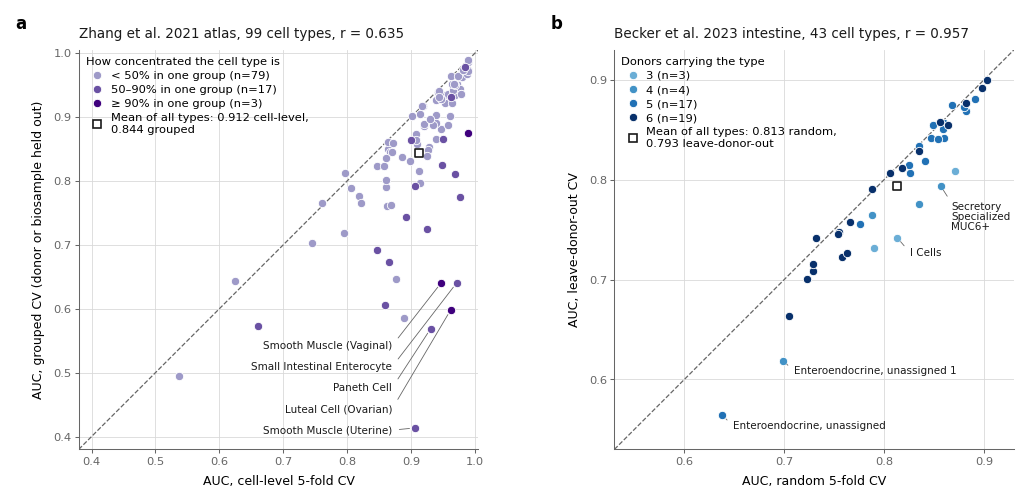

In [3]:
# ── Figure: a, atlas grouped CV; b, Becker 2023 leave-donor-out ────────────────
with plt.rc_context(PANEL_RC):
    fig, (axA, axB) = plt.subplots(1, 2, figsize=(WIDTH, 3.25))

    # a -- atlas
    diagonal(axA, 0.38, 1.005)
    for k, (name, lo, hi, col, _) in enumerate(SHARE_BINS):
        s = ok[ok.share_bin == name]
        axA.scatter(s.auc_cell, s.auc_grouped, s=DOT, color=col, edgecolor="white",
                    linewidth=0.4, zorder=3 + k)
    worst = ok.nsmallest(5, "delta").sort_values("auc_grouped")
    label_points(axA, worst, "auc_cell", "auc_grouped",
                 slots=[0.41, 0.443, 0.476, 0.509, 0.542], text_x=0.87, ha="right",
                 obstacles=ok[["auc_cell", "auc_grouped"]].to_numpy())
    axA.set_xticks(np.arange(0.4, 1.01, 0.1)); axA.set_yticks(np.arange(0.4, 1.01, 0.1))
    axA.set_xlabel("AUC, cell-level 5-fold CV")
    axA.set_ylabel("AUC, grouped CV (donor or biosample held out)")
    axA.set_title(f"Zhang et al. 2021 atlas, {len(ok)} cell types, "
                  f"r = {ok.auc_cell.corr(ok.auc_grouped):.3f}", loc="left", color=INK)
    style(axA)
    hA = [Line2D([], [], ls="", marker="o", ms=4, mfc=c, mec="white", mew=0.4,
                 label=f"{text} (n={int((ok.share_bin == n).sum())})")
          for n, _, _, c, text in SHARE_BINS]
    hA.append(mean_marker(axA, ok.auc_cell.mean(), ok.auc_grouped.mean(),
                          f"Mean of all types: {ok.auc_cell.mean():.3f} cell-level,\n"
                          f"{ok.auc_grouped.mean():.3f} grouped"))
    axA.legend(handles=hA, loc="upper left", frameon=False, handletextpad=0.2,
               labelspacing=0.35, borderaxespad=0.2, alignment="left",
               title="How concentrated the cell type is", title_fontsize=5.5)

    # b -- Becker 2023
    diagonal(axB, 0.53, 0.93)
    for nd, sub in m.groupby("n_donor"):
        axB.scatter(sub.auc_random, sub.auc_donor, s=DOT, color=DONOR_RAMP[nd],
                    edgecolor="white", linewidth=0.4, zorder=3)
    worstB = m.reindex(m.delta.abs().sort_values(ascending=False).index).head(4) \
              .sort_values("auc_donor")
    # Four labels, all with open space below the diagonal: each sits beside its
    # point. The long one near the right edge is wrapped into a narrow block so
    # it fits between its point and the axis edge.
    label_beside(axB, worstB, "auc_random", "auc_donor",
                 place={"Secretory Specialized MUC6+": (5, -15, "left", (0.0, 1.0)),
                        "I Cells": (6, -7, "left", (0.0, 0.5))})
    axB.set_xticks(np.arange(0.6, 0.91, 0.1)); axB.set_yticks(np.arange(0.6, 0.91, 0.1))
    axB.set_xlabel("AUC, random 5-fold CV")
    axB.set_ylabel("AUC, leave-donor-out CV")
    axB.set_title(f"Becker et al. 2023 intestine, {len(m)} cell types, "
                  f"r = {m.auc_random.corr(m.auc_donor):.3f}", loc="left", color=INK)
    style(axB)
    hB = [Line2D([], [], ls="", marker="o", ms=4, mfc=c, mec="white", mew=0.4,
                 label=f"{nd} (n={int((m.n_donor == nd).sum())})")
          for nd, c in DONOR_RAMP.items()]
    hB.append(mean_marker(axB, m.auc_random.mean(), m.auc_donor.mean(),
                          f"Mean of all types: {m.auc_random.mean():.3f} random,\n"
                          f"{m.auc_donor.mean():.3f} leave-donor-out"))
    axB.legend(handles=hB, loc="upper left", frameon=False, handletextpad=0.2,
               labelspacing=0.35, borderaxespad=0.2, alignment="left",
               title="Donors carrying the type", title_fontsize=5.5)

    fig.tight_layout(w_pad=2.5)
    for ax, letter in ((axA, "a"), (axB, "b")):
        fig.text(ax.get_position().x0 - 0.06, ax.get_position().y1 + 0.035, letter,
                 fontsize=8, fontweight="bold", va="bottom", ha="left")

    src = pd.concat([
        pd.DataFrame({"panel": "a", "cohort": "Zhang2021_atlas", "cell_type": ok.cell_type,
                      "auc_standard_cv": ok.auc_cell, "auc_strict_cv": ok.auc_grouped,
                      "delta": ok.delta, "largest_group_share": ok.largest_group_share,
                      "share_bin": ok.share_bin, "n_donor": np.nan}),
        pd.DataFrame({"panel": "b", "cohort": "Becker2023_intestine", "cell_type": m.cell_type,
                      "auc_standard_cv": m.auc_random, "auc_strict_cv": m.auc_donor,
                      "delta": m.delta, "largest_group_share": np.nan,
                      "share_bin": "", "n_donor": m.n_donor}),
    ], ignore_index=True)
    savefig(fig, OUT, "scatac_grouped_cv_auc", data=src)
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
rho = spearmanr(ok.largest_group_share, ok.delta)
print(f"a  {len(ok)} of {len(d)} tasks evaluable ({n_drop} lose a fold's positives)")
print(f"   mean AUC {ok.auc_cell.mean():.3f} cell-level vs {ok.auc_grouped.mean():.3f} grouped; "
      f"{int((ok.delta < -0.10).sum())} tasks lose > 0.10")
print(f"   Spearman rho(largest-group share, AUC change) = {rho.statistic:.2f}, p = {rho.pvalue:.1e}")
for name, *_ in SHARE_BINS:
    s = ok[ok.share_bin == name]
    print(f"   {name:<7} n={len(s):>2}  mean AUC change {s.delta.mean():+.3f}  "
          f"(> 0.10 lost: {int((s.delta < -0.10).sum())})")
mr, md = m.auc_random.mean(), m.auc_donor.mean()
print(f"b  {len(m)} tasks; mean AUC {mr:.3f} random vs {md:.3f} leave-donor-out "
      f"({md - mr:+.3f}); |change| < 0.05 in {int((m.delta.abs() < 0.05).sum())}/{len(m)}")

a  99 of 108 tasks evaluable (9 lose a fold's positives)
   mean AUC 0.912 cell-level vs 0.844 grouped; 20 tasks lose > 0.10
   Spearman rho(largest-group share, AUC change) = -0.62, p = 7.7e-12
   < 50%   n=79  mean AUC change -0.038  (> 0.10 lost: 5)
   50-90%  n=17  mean AUC change -0.175  (> 0.10 lost: 12)
   >= 90%  n= 3  mean AUC change -0.262  (> 0.10 lost: 3)
b  43 tasks; mean AUC 0.813 random vs 0.793 leave-donor-out (-0.020); |change| < 0.05 in 36/43
